In [1]:
import os
import pandas as pd
import numpy as np

from lightgbm import LGBMClassifier

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, make_scorer, f1_score
from sklearn.utils.class_weight import compute_class_weight

In [2]:
# load final model data
df = pd.read_csv("model_data_final_v2.csv")

# multiclass mapping of target varible: InjurySeverity
df['InjurySeverity'].value_counts()
df['InjurySeverity'] = df['InjurySeverity'].map({5:0, 4:0, 3:1, 2:1, 1:2})
df['InjurySeverity'].value_counts()

# drop redundant cols
drop_cols = ['IncidentID', 
             'IncidentDateTime',
             'has_child',
             'first_harmful_fixed_object',
             'is_age_middle']
df.drop(drop_cols, axis = 1, inplace = True)

# rename column
df.rename(columns = {'first_hamrful_guardrail': 'first_harmful_guardrail'}, inplace = True)

In [3]:
# features and target variable
X = df.drop('InjurySeverity', axis = 1).copy()
y = df['InjurySeverity'].copy()

# train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify = y, test_size = 0.3, random_state = 42)

In [4]:
# compute class weights and map to sample weights
classes = np.unique(y_train)
class_weights = compute_class_weight(class_weight = 'balanced', classes = classes, y = y_train)
weight_dict = {i: class_weights[i] for i in range(len(class_weights))}
sample_weights = y_train.map(weight_dict)

In [5]:
# define model
lgb = LGBMClassifier(
    objective = 'multiclass',
    class_weight = None, # sample weights used
    num_class = 3,
    random_state = 42,
    n_jobs = -1,
    verbosity = -1
)

# hyperparameter grid
param_grid = {
    'max_depth': [7],
    'learning_rate': [0.2],
    'n_estimators': [100],
    'min_child_samples': [5],
    'subsample': [0.8],
    'colsample_bytree': [0.8],
    'reg_alpha': [0.1],
    'reg_lambda': [0.1]
}

# stratified 5-fold CV
cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)

# use macro F1 as scoring metric
scorer = make_scorer(f1_score, average = 'macro')

# grid search with sample weights
grid_search = GridSearchCV(
    estimator = lgb,
    param_grid = param_grid,
    cv = cv,
    scoring = scorer,
    verbose = 1,
    n_jobs = -1
)

grid_search.fit(X_train, y_train, sample_weight = sample_weights)
best_model = grid_search.best_estimator_
print(f"\nBest parameters: {grid_search.best_params_}\n")

# predict on test set
y_pred = best_model.predict(X_test)

Fitting 5 folds for each of 1 candidates, totalling 5 fits

Best parameters: {'colsample_bytree': 0.8, 'learning_rate': 0.2, 'max_depth': 7, 'min_child_samples': 5, 'n_estimators': 100, 'reg_alpha': 0.1, 'reg_lambda': 0.1, 'subsample': 0.8}



In [6]:
# model evaluation
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, target_names = ['KA', 'BC', 'O'])

# confusion matrix
class_names = ['KA', 'BC', 'O']
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(
    cm,
    index = [f'Actual_{cls}' for cls in class_names],
    columns = [f'Predicted_{cls}' for cls in class_names]
)

print(f"LightGBM")
print(f"Accuracy: {round(accuracy, 4)}\n")
print(f"Classification Report: \n{report}\n")
print(f"Confusion Matrix: \n{cm_df}\n")

report_dict = classification_report(y_test, y_pred, target_names = ['KA', 'BC', 'O'], output_dict = True)

f1_scores = [
    report_dict['KA']['f1-score'],
    report_dict['BC']['f1-score'],
    report_dict['O']['f1-score']
]

harmonic_mean_f1 = len(f1_scores) / sum(1.0 / f for f in f1_scores if f > 0)
print(f"Harmonic Mean of F1-scores: {round(harmonic_mean_f1, 4)}")

LightGBM
Accuracy: 0.6374

Classification Report: 
              precision    recall  f1-score   support

          KA       0.33      0.26      0.30        34
          BC       0.39      0.36      0.37       148
           O       0.74      0.79      0.76       364

    accuracy                           0.64       546
   macro avg       0.49      0.47      0.48       546
weighted avg       0.62      0.64      0.63       546


Confusion Matrix: 
           Predicted_KA  Predicted_BC  Predicted_O
Actual_KA             9            13           12
Actual_BC             9            53           86
Actual_O              9            69          286

Harmonic Mean of F1-scores: 0.4073


In [7]:
# retrain full dataset using best hyperparameters
final_model = LGBMClassifier(
    objective = 'multiclass',
    num_class = 3,
    random_state = 42,
    n_jobs = -1,
    verbosity = -1,
    **grid_search.best_params_
)

final_model.fit(X, y)

LGBMClassifier(colsample_bytree=0.8, learning_rate=0.2, max_depth=7,
               min_child_samples=5, n_jobs=-1, num_class=3,
               objective='multiclass', random_state=42, reg_alpha=0.1,
               reg_lambda=0.1, subsample=0.8, verbosity=-1)

In [8]:
import shap

# initialize shap explainer
explainer = shap.Explainer(final_model, X, feature_names = X.columns)

# compute SHAP values for the test set
shap_values = explainer(X)

 98%|===================| 5348/5460 [00:33<00:00]        

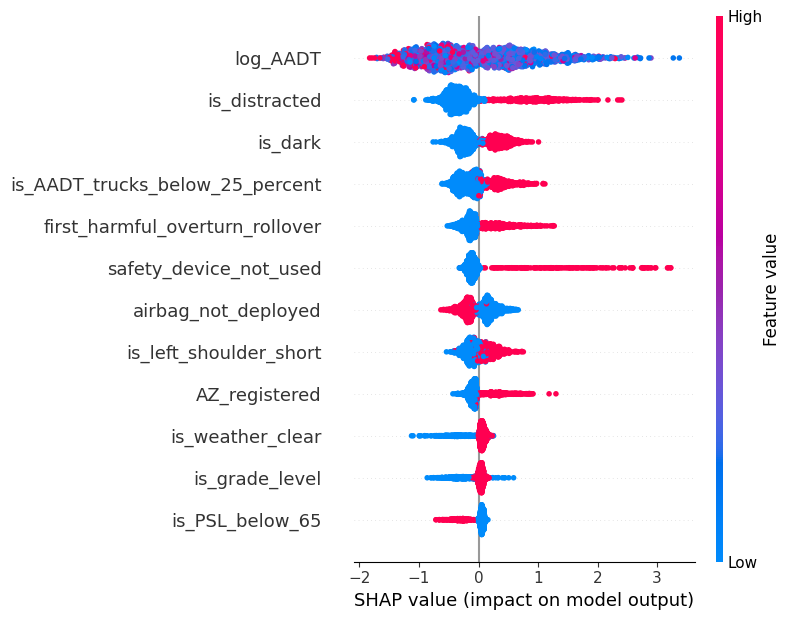

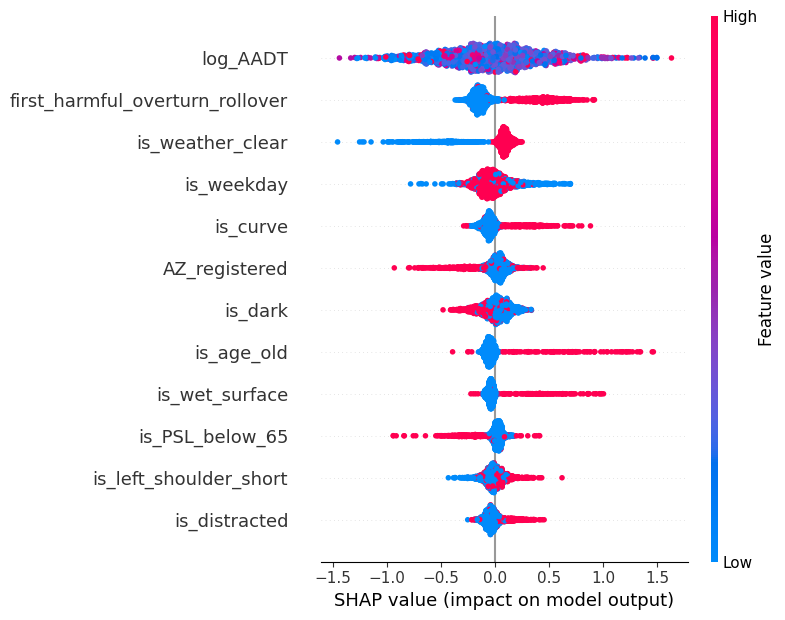

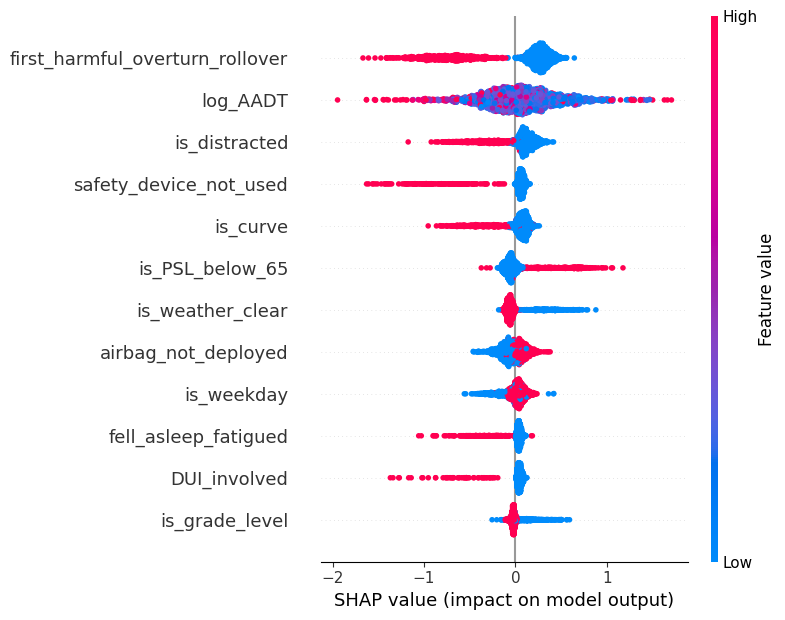

In [9]:
# shap summary plots
shap.summary_plot(shap_values[:,:,0], X, max_display = 12)
shap.summary_plot(shap_values[:,:,1], X, max_display = 12)
shap.summary_plot(shap_values[:,:,2], X, max_display = 12)

In [ ]:
# save shap summary plots
import matplotlib.pyplot as plt

# class KA
plt.figure()
shap.summary_plot(shap_values[:,:,0], X, show = False, max_display = 12)
plt.title("(a) SHAP summary for class KA", fontweight = 'bold')
plt.savefig("output/shap_summary_plots/shap_summary_class_KA.png", dpi = 1200, bbox_inches = 'tight')
plt.close()

# class BC
plt.figure()
shap.summary_plot(shap_values[:,:,1], X, show = False, max_display = 12)
plt.title("(b) SHAP summary for class BC", fontweight = 'bold')
plt.savefig("output/shap_summary_plots/shap_summary_class_BC.png", dpi = 1200, bbox_inches = 'tight')
plt.close()

# class O
plt.figure()
shap.summary_plot(shap_values[:,:,2], X, show = False, max_display = 12)
plt.title("(c) SHAP summary for class O", fontweight = 'bold')
plt.savefig("output/shap_summary_plots/shap_summary_class_O.png", dpi = 1200, bbox_inches = 'tight')
plt.close()

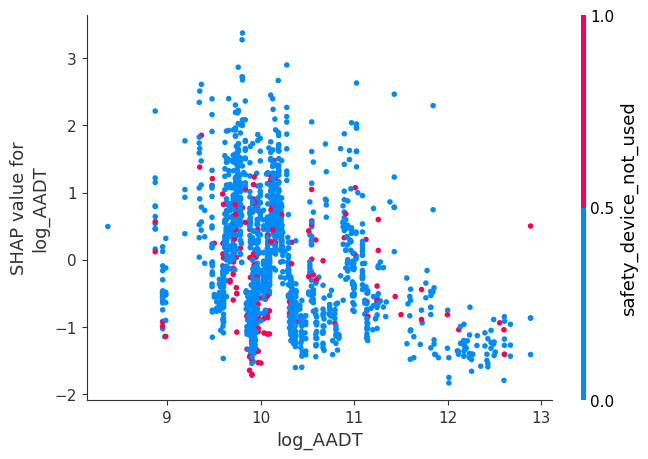

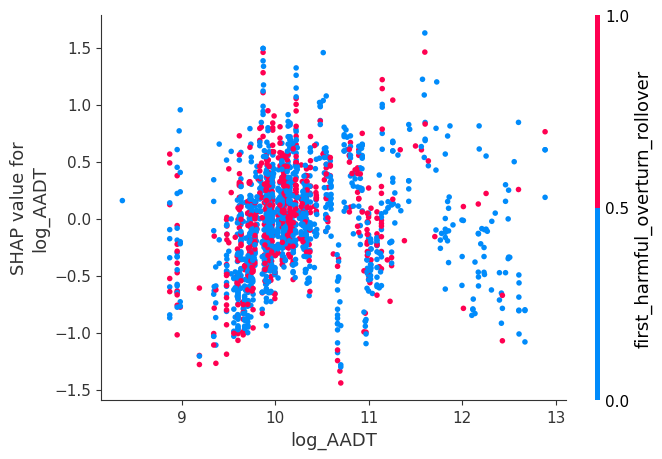

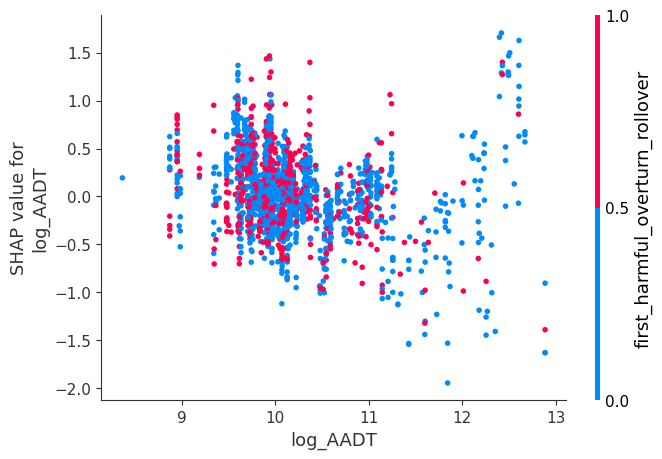

In [10]:
# DEPENDENCE PLOTS

# extract shap values for each class as 2D NumPy arrays
shap_values_class_0 = shap_values[..., 0].values # KA
shap_values_class_1 = shap_values[..., 1].values # BC
shap_values_class_2 = shap_values[..., 2].values # O

shap.dependence_plot("log_AADT", shap_values_class_0, X)
shap.dependence_plot("log_AADT", shap_values_class_1, X)
shap.dependence_plot("log_AADT", shap_values_class_2, X)

In [ ]:
# save shap dependency analysis

# class KA
plt.figure()
shap.dependence_plot("log_AADT", shap_values_class_0, X, show = False)
plt.title("(a) SHAP dependence plot for AADT (class KA)", fontweight = 'bold')
plt.savefig("output/shap_dependency_analysis/shap_dependence_class_KA.png", dpi = 1200, bbox_inches = 'tight')
plt.close()

# class BC
plt.figure()
shap.dependence_plot("log_AADT", shap_values_class_1, X, show = False)
plt.title("(b) SHAP dependence plot for AADT (class BC)", fontweight = 'bold')
plt.savefig("output/shap_dependency_analysis/shap_dependence_class_BC.png", dpi = 1200, bbox_inches = 'tight')
plt.close()

# class O
plt.figure()
shap.dependence_plot("log_AADT", shap_values_class_2, X, show = False)
plt.title("(c) SHAP dependence plot for AADT (class O)", fontweight = 'bold')
plt.savefig("output/shap_dependency_analysis/shap_dependence_class_O.png", dpi = 1200, bbox_inches = 'tight')
plt.close()

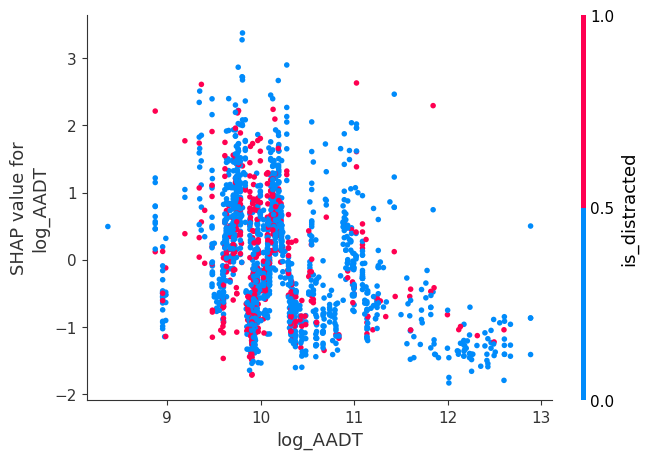

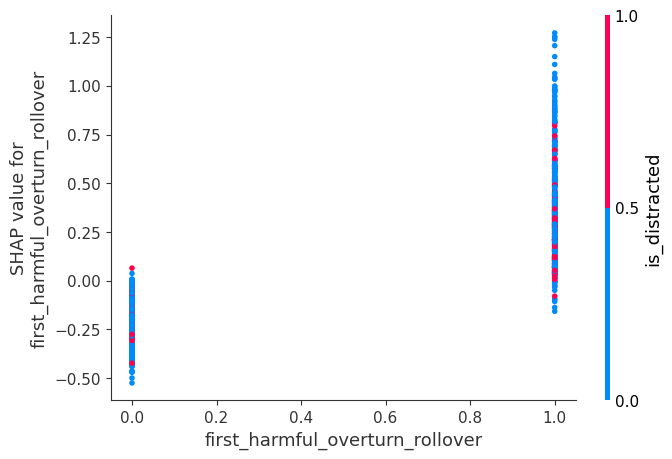

In [11]:
# check interaction with other variables
shap.dependence_plot("log_AADT", shap_values_class_0, X, interaction_index = 'is_distracted')
shap.dependence_plot("first_harmful_overturn_rollover", shap_values_class_0, X, interaction_index = 'is_distracted')